Importiamo le librerie necessarie al programma

In [4]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit
rng = np.random.default_rng(6302026)

Creazione della funzione di partenza  

In [5]:
B = 20
I0 = 400
alfa = 0.90
delta = 5.20
def E (x):
    E = (np.sinc(alfa * x))**2
    return E
def C (x):
    C = (np.cos(delta*x))**2
    return C
def mu (x):
    mu_ = B + I0 * E(x) *C(x)
    return mu_

Costruzione del modello

In [6]:
x = np.linspace(-5, 5, 161)
Inviluppo = B +I0*E(x)
print(np.all(mu(x) >= 0))
print(np.all(np.isfinite(mu(x))))
print(np.all(mu(x) == mu(-x)))
print( mu(0) == B + I0)

True
True
True
True


Generazione del grafico

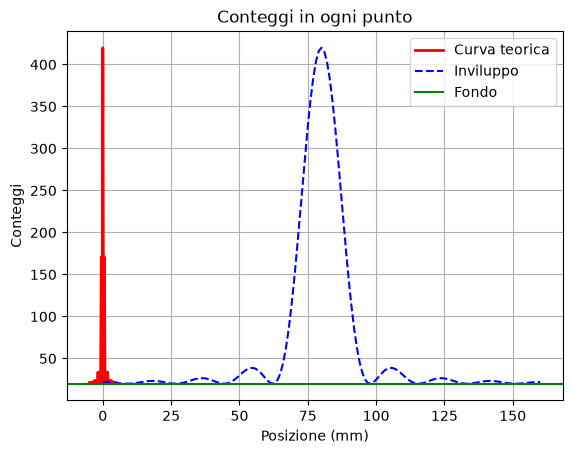

In [7]:
fig, ax = plt.subplots()
ax.plot(x, mu(x), "r-", lw= 2, label = "Curva teorica")
ax.plot(Inviluppo, "b--", lw = 1.5, label = "Inviluppo")
ax.axhline(B, color = "g", label = "Fondo")
ax.set(xlabel = "Posizione (mm)", ylabel = "Conteggi", title = "Conteggi in ogni punto")
ax.legend()
ax.grid()
plt.show()

Simulazione di una acquisizione

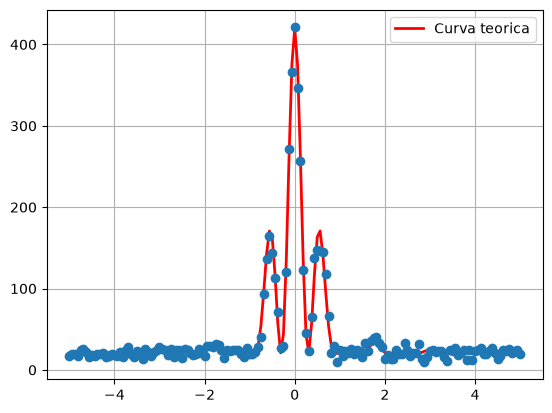

In [14]:
n = rng.poisson(mu(x))
errori = []
for n_ in n: 
    if n_ == 0: 
        sigma = np.sqrt(n)
    else:
        sigma = 1
    errori.append(sigma)
fig, ax = plt.subplots()
ax.plot(x, mu(x), "r-", lw= 2, label = "Curva teorica")
ax.errorbar(x, n, yerr = errori, fmt = "o")
ax.legend()
ax.grid()
plt.show()

Calcolo conteggi

In [13]:
Nc = np.sum(n[(abs(x) < 1.2)])
muc = np.sum(mu(abs(x)< 1.2))
sigma_Nc = np.sqrt(muc)
scarto = Nc - muc
z = scarto/sigma_Nc
print(z)


-210.2651557306619


Ripetere la simulazione

In [ ]:
M = 2000
centrale = abs(x) < 1.2
Nc_simulati = []
for j in range(M):
    ni = rng.poisson(mu(x))
    Nc_= np.sum(ni[centrale])
    Nc_simulati.append(Nc_)
Nc_simulati = np.array(Nc_simulati)
print(f"media= {Nc_simulati.mean():.2f}")
print(f"deviazione standard = {Nc_simulati.std(ddof =1)}")
errore_media = Nc_simulati.std(ddof = 1) / np.sqrt(M)
print(errore_media)